# EDA 2: Dwelling Features and Amenities

This notebook explores how dwelling configuration, interior systems, basement and garage features, bathroom count, and outdoor amenities vary with sale price. It complements the first EDA, which focused on living area, neighborhood, overall quality, age, and general outliers. Group summaries show sample sizes alongside medians; observed differences are descriptive, not causal.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
train_data_df = pd.read_csv('../data/train.csv')
print(f'Training rows: {len(train_data_df):,}')
print(f'Columns: {train_data_df.shape[1]}')
train_data_df.head()

Training rows: 1,460
Columns: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Dwelling configuration

Compare sale prices across building types and house styles. Categories with very few sales can have unstable medians, so check the counts before drawing conclusions.

,count,median
BldgType,,
TwnhsE,114,172200.0
1Fam,1220,167900.0
Twnhs,43,137500.0
Duplex,52,135980.0
2fmCon,31,127500.0


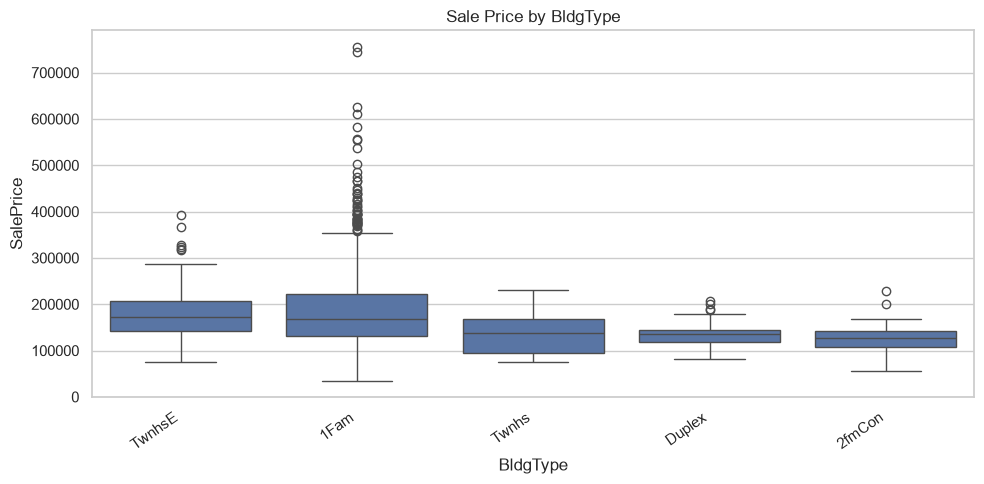

,count,median
HouseStyle,,
2.5Fin,8,194000.0
2Story,445,190000.0
SLvl,65,164500.0
1Story,726,154750.0
SFoyer,37,135960.0
2.5Unf,11,133900.0
1.5Fin,154,132000.0
1.5Unf,14,111250.0


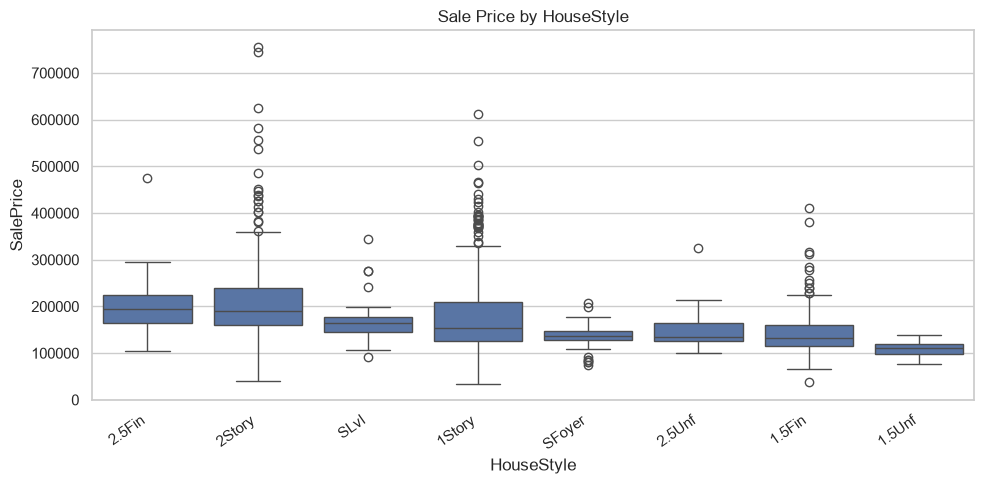

In [3]:
for feature in ['BldgType', 'HouseStyle']:
    summary = (
        train_data_df.groupby(feature, observed=True)['SalePrice']
        .agg(count='size', median='median')
        .sort_values('median', ascending=False)
    )
    display(summary)
    order = summary.index.tolist()
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=train_data_df, x=feature, y='SalePrice', order=order)
    plt.xticks(rotation=35, ha='right')
    plt.title(f'Sale Price by {feature}')
    plt.tight_layout()
    plt.show()

## Interior systems and finish

KitchenQual and HeatingQC are ordered ratings in the data dictionary. Compare their distributions and sale-price summaries without treating the numeric-looking category labels as continuous measurements.

,count,median
KitchenQual,,
Ex,100,316750.0
Fa,39,115000.0
Gd,586,201400.0
TA,735,137000.0


,count,median
HeatingQC,,
Ex,741,194700.0
Fa,49,123500.0
Gd,241,152000.0
Po,1,87000.0
TA,428,135000.0


,count,median
CentralAir,,
N,95,98000.0
Y,1365,168000.0


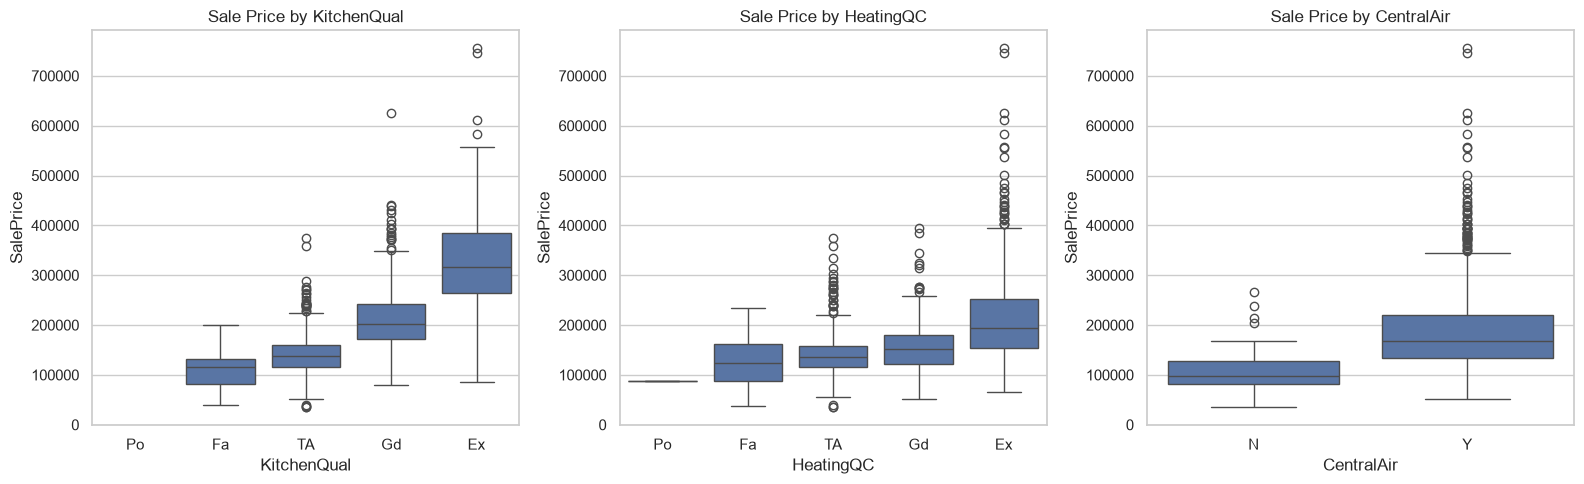

In [4]:
quality_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for axis, feature, order in [
    (axes[0], 'KitchenQual', quality_order),
    (axes[1], 'HeatingQC', quality_order),
    (axes[2], 'CentralAir', ['N', 'Y']),
]:
    summary = train_data_df.groupby(feature, dropna=False, observed=True)['SalePrice'].agg(count='size', median='median')
    display(summary)
    sns.boxplot(data=train_data_df, x=feature, y='SalePrice', order=order, ax=axis)
    axis.set_title(f'Sale Price by {feature}')

plt.tight_layout()
plt.show()

## Basement and garage features

Blank ratings and finish values in these fields indicate that a home may not have that feature. Label missing values as `None` to keep absence in the comparisons.

,count,median
BsmtFinType1,,
None,37,101800.0
Unf,430,161750.0
LwQ,74,139000.0
Rec,133,142000.0
BLQ,148,139100.0
ALQ,220,149250.0
GLQ,418,213750.0


,count,median
GarageFinish,,
None,81,100000.0
Unf,605,135000.0
RFn,422,190000.0
Fin,352,215000.0


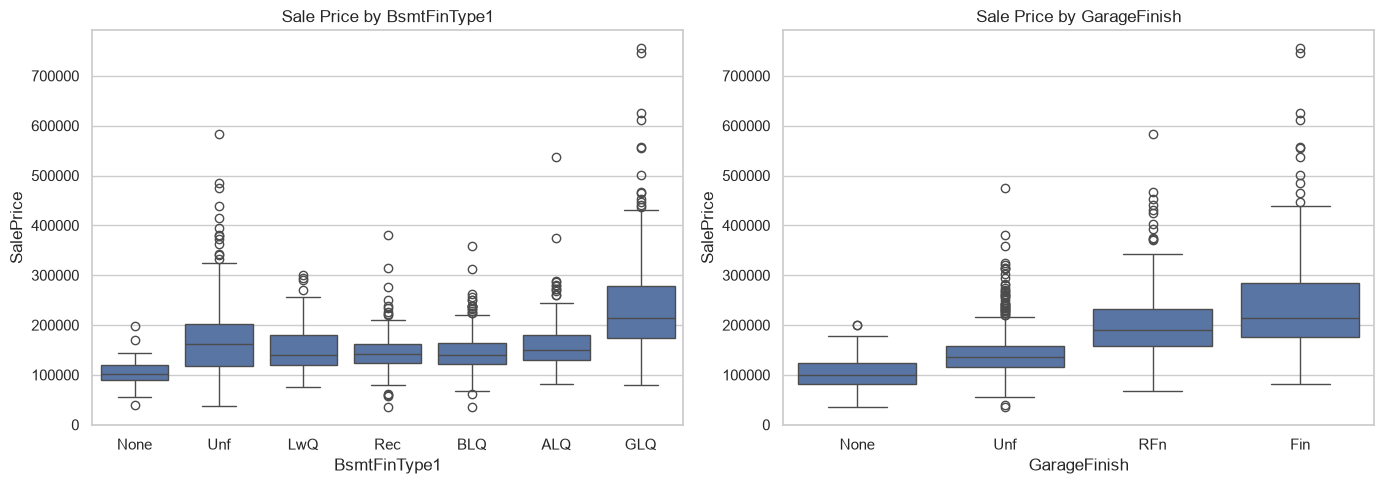

,count,median
TotalBathrooms,,
1.0,228,112250.0
1.5,129,142500.0
2.0,456,145000.0
2.5,295,184000.0
3.0,186,213750.0
3.5,144,247000.0
4.0,13,299800.0
4.5,7,250000.0
5.0,1,145900.0


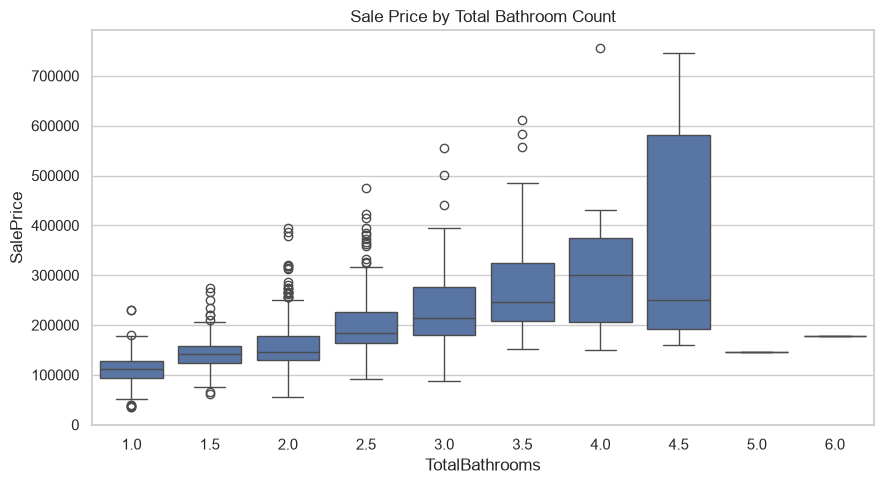

,Feature,Area,Count,MedianSalePrice
0,WoodDeckSF,None,761.0,144152.0
1,WoodDeckSF,Present,699.0,187000.0
2,OpenPorchSF,None,656.0,136700.0
3,OpenPorchSF,Present,804.0,192000.0
4,EnclosedPorch,None,1252.0,170000.0
5,EnclosedPorch,Present,208.0,133350.0
6,3SsnPorch,None,1436.0,162000.0
7,3SsnPorch,Present,24.0,187500.0
8,ScreenPorch,None,1344.0,160000.0
9,ScreenPorch,Present,116.0,175000.0


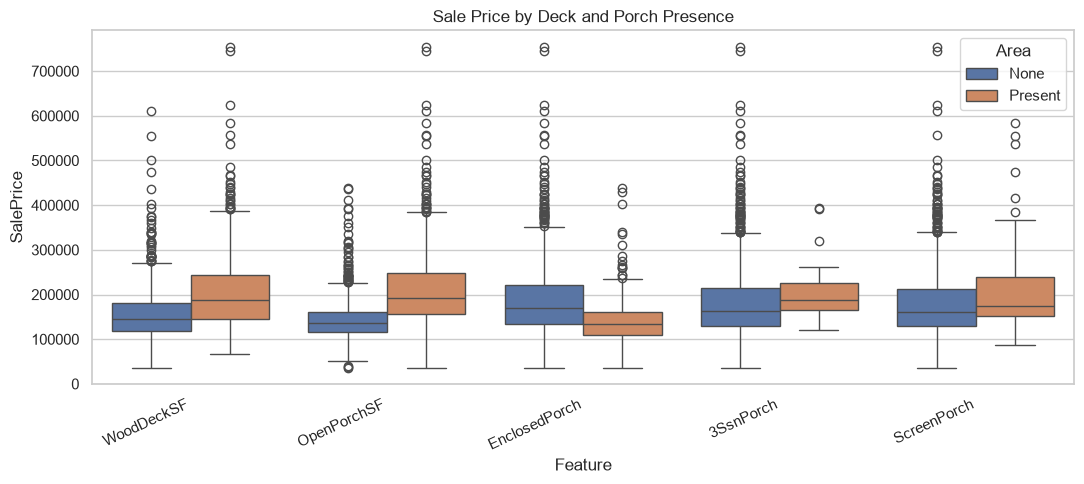

In [5]:
feature_orders = {
    'BsmtFinType1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'GarageFinish': ['None', 'Unf', 'RFn', 'Fin'],
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, (feature, order) in zip(axes, feature_orders.items()):
    plot_data = train_data_df.assign(**{feature: train_data_df[feature].fillna('None')})
    summary = plot_data.groupby(feature, observed=True)['SalePrice'].agg(count='size', median='median').reindex(order)
    display(summary)
    sns.boxplot(data=plot_data, x=feature, y='SalePrice', order=order, ax=axis)
    axis.set_title(f'Sale Price by {feature}')

plt.tight_layout()
plt.show()

train_data_df['TotalBathrooms'] = (
    train_data_df['FullBath']
    + 0.5 * train_data_df['HalfBath']
    + train_data_df['BsmtFullBath']
    + 0.5 * train_data_df['BsmtHalfBath']
)
bath_summary = train_data_df.groupby('TotalBathrooms', observed=True)['SalePrice'].agg(count='size', median='median').sort_index()
display(bath_summary)

plt.figure(figsize=(9, 5))
sns.boxplot(data=train_data_df, x='TotalBathrooms', y='SalePrice')
plt.title('Sale Price by Total Bathroom Count')
plt.tight_layout()
plt.show()

outdoor_features = ['WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']
outdoor_rows = []
for feature in outdoor_features:
    presence = train_data_df[feature].gt(0).map({False: 'None', True: 'Present'})
    grouped = train_data_df.assign(Feature=presence).groupby('Feature', observed=True)['SalePrice'].agg(count='size', median='median')
    for category, values in grouped.iterrows():
        outdoor_rows.append({'Feature': feature, 'Area': category, 'Count': values['count'], 'MedianSalePrice': values['median']})
outdoor_summary = pd.DataFrame(outdoor_rows)
display(outdoor_summary)

plot_data = train_data_df[outdoor_features + ['SalePrice']].melt(id_vars='SalePrice', var_name='Feature', value_name='Area')
plot_data['Area'] = plot_data['Area'].gt(0).map({False: 'None', True: 'Present'})
plt.figure(figsize=(11, 5))
sns.boxplot(data=plot_data, x='Feature', y='SalePrice', hue='Area', hue_order=['None', 'Present'])
plt.xticks(rotation=25, ha='right')
plt.title('Sale Price by Deck and Porch Presence')
plt.tight_layout()
plt.show()